## NB1 - Baseline


Setup

In [1]:
QUICK = False #run in quick mode if cached results for demo
RERUN = set() #when quick = false, try to load any cached results to avoid rerunning code (sessions kept timing out and had to rerun long cells)

import json, random, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torchvision import datasets, transforms
from PIL import Image

device = ('cuda' if torch.cuda.is_available() else
          'mps' if torch.backends.mps.is_available() else 'cpu')

IMG_SIZE = 64 #both dataset images fed to network at 64x64
SEEDS = [0, 1, 2, 3, 4] #these lines might be unused but i'm not sure and i'd rather not remove them just in case
if QUICK:
  EPOCHS = 3
else:
  EPOCHS = 60

#relative paths to try and keep data location consistent
DATA_DIR = Path("data")
RESULTS_DIR = Path("results") / "NB1"
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed): #seed all 3 to try and keep weights/data order/etc relatively consistent
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)

print('torch', torch.__version__, '| device:', device, '| QUICK:', QUICK)

torch 2.14.1+cu130 | device: cuda | QUICK: False


In [2]:
from google.colab import drive #colab only, delete before submitting!!
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/nb1_results
!rm -rf results/nb1 && mkdir -p results && ln -s /content/drive/MyDrive/nb1_results results/nb1

Mounted at /content/drive


In [ ]:
from google.colab import drive; drive.mount('/content/drive') #colab only, delete before submitting!!
!unzip -o -q "/content/drive/MyDrive/nb1_results.zip" "results/NB1/*" -d .

Data (not sure if i wrote but having colour in the shape images made it impossible for it to learn, accuracy went up massively once converted to black/white)

In [3]:
datasets.DTD(DATA_DIR, split="train", partition=1, download=True) #download dtd dataset

100%|██████████| 625M/625M [00:25<00:00, 24.8MB/s]


Dataset DTD
    Number of datapoints: 1880
    Root location: data
    split=train, partition=1

In [4]:
from google.colab import drive; drive.mount('/content/drive') #colab only, delete before submitting!!
!unzip -q -n "/content/drive/MyDrive/dataset.zip" -d data/shapes_raw

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
from collections import defaultdict
from torch.utils.data import TensorDataset

SHAPES_RAW = DATA_DIR / "shapes_raw" #unzipped shapes folder, too large for submission
SHAPES_NPZ = DATA_DIR / "shapes_subset.npz" #^take subset of images
SHAPE_CLASSES = ["Circle", "Heptagon", "Hexagon", "Nonagon", "Octagon", "Pentagon", "Square", "Star", "Triangle"] #all of the different shape types in the dataset
NUM_PER_SPLIT = {"train": 10, "val": 100, "test": 100} #ratio of train/validation/test
N_TOTAL = sum(NUM_PER_SPLIT.values()) #total images (had to keep changing the ratio so this was easier than hardcoding)
MIN_SIZE = 12 #remove shapes smaller than 12px because resizing would make some classes indistinguishable

def shape_size(img):
  corners = np.array([img[0,0], img[0,-1], img[-1,0], img[-1,-1]]) #to measure shape size, find where bg and shape colour differ and measure
  colours, counts = np.unique(corners, axis=0, return_counts=True) #take colours of all corners (some shapes were in a corner when i had it take the colour from only one corner and broke this part)
  bg = colours[np.argmax(counts)] #take the most common corner (shape isn't going to be in 1< corner so guarantees it's actually the background)
  mask = (img != bg).any(axis=-1) #compares each pixel w/ background colour from the 3 RGB channels
  rows, columns = np.where(mask) #lists coords of each pixel where img!=bg
  width = np.max(columns) - np.min(columns) + 1
  height = np.max(rows) - np.min(rows) + 1
  return max(width, height) #returns the larger of width/height to get estimate for size of shape

def remove_colour(img):
    x = img.astype(np.float32) #pixel values -> decimals
    corners = np.array([x[0, 0], x[0, -1], x[-1, 0], x[-1, -1]])
    bg = np.median(corners, axis=0)
    dist = np.abs(x - bg).sum(axis=-1) #measure how far each pixel's colour is from the bg
    grey = dist / dist.max() #divides all distances by the largest distance, ends up with greyscale instead of RGB
    return np.repeat((grey * 255).astype(np.uint8)[..., None], 3, axis=-1) #converting back to image by copying greyscale channel 3x so it stays the same size

def build_shape_subset(SHAPES_RAW, SHAPES_NPZ, seed=0):
  files = sorted(SHAPES_RAW.rglob("*.png")) #sort images so the same subset is given per seed
  shape_class = defaultdict(list)
  for f in files: #goes through every png and since every image is named [shape]_[numbers], it splits at the underscore to get class of shape
    shape = f.name.split("_")[0]
    shape_class[shape].append(f)
  rng = np.random.default_rng(seed) #fixed seed so reproducible
  data = {s: {"image": [], "class": [], "size": []} for s in NUM_PER_SPLIT}
  for label, name in enumerate(SHAPE_CLASSES):
    chosen = []
    for f in rng.permutation(shape_class[name]): #go through each class in random order + choose the first n_total images from that class
      array = np.asarray(Image.open(f).convert("RGB"))
      if shape_size(array) * IMG_SIZE / array.shape[1] >= MIN_SIZE: # ^ only choose images where shape > minsize
        chosen.append(f)
      if len(chosen) == N_TOTAL:
        break
    splits = {} #splitting images into train/val/test, 0->NUM_PER_SPLIT = train, etc.
    start = 0 #this code might be a bit inefficient i had the values hardcoded until i had to change them and it was annoying
    for split, n in NUM_PER_SPLIT.items():
      splits[split] = chosen[start:start + n]
      start = start + n
    for split, split_files in splits.items():
      for f in split_files: #process each image: measure shape size, resize to 64x64, remove colour
        img = Image.open(f).convert("RGB")
        array = np.asarray(img) # convert image into an array
        size = shape_size(array) * IMG_SIZE/array.shape[1]
        resized = remove_colour(np.asarray(img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)))
        data[split]["image"].append(resized)
        data[split]["class"].append(label)
        data[split]["size"].append(size)
  arrays = {}
  for split in data: #put each split-up image into an array and save into one file
    arrays["image_" + split] = np.array(data[split]["image"])
    arrays["class_" + split] = np.array(data[split]["class"])
    arrays["size_" + split] = np.array(data[split]["size"])
  np.savez_compressed(SHAPES_NPZ, classes=SHAPE_CLASSES, **arrays)

if not SHAPES_NPZ.exists():
    build_shape_subset(SHAPES_RAW, SHAPES_NPZ)
shapes = np.load(SHAPES_NPZ)

def build_tensor_dataset(split):
  images = torch.from_numpy(shapes["image_" + split]).float() / 255
  images = images.permute(0, 3, 1, 2)
  labels = torch.from_numpy(shapes["class_" + split]).long()
  return TensorDataset(images, labels)
shapes_train = build_tensor_dataset("train")
shapes_val   = build_tensor_dataset("val")
shapes_test  = build_tensor_dataset("test")

class InMemory(torch.utils.data.Dataset):
  #this is mainly for trying to handle dtd images, as the jpegs take a while to use (~20 second to epoch) without crop/flip
  def __init__(self, items, transform):
    self.items, self.transform = items, transform
  def __len__(self):
    return len(self.items)
  def __getitem__(self, i):
    x, y = self.items[i]
    return self.transform(x).float() / 255, y

def preload_dtd(split):
  #resizing to 128 means a 64x64 crop still shows enough texture
  tf = transforms.Compose([transforms.Resize(128), transforms.PILToTensor()])
  ds = datasets.DTD(DATA_DIR, split=split, partition=1, transform=tf, download=True)
  return [ds[i] for i in range(len(ds))]

#load dtd, except in quick mode on a machine that doesnt have it downloaded
if not QUICK or (DATA_DIR / "dtd").exists():
  DTD_CLASSES = datasets.DTD(DATA_DIR, split="train", partition=1, download=True).classes
  #train = random 64x64 crop/flip to increase amount of images it can learn from
  dtd_train = InMemory(preload_dtd("train"), transforms.Compose([transforms.RandomCrop(IMG_SIZE), transforms.RandomHorizontalFlip()]))
  #fixed centre crop otherwise so evaluation stays constnat
  dtd_val   = InMemory(preload_dtd("val"),  transforms.CenterCrop(IMG_SIZE))
  dtd_test  = InMemory(preload_dtd("test"), transforms.CenterCrop(IMG_SIZE))
else:
  #dtd not available
  DTD_CLASSES = None
  dtd_train = None
  dtd_val = None
  dtd_test = None

In [7]:
print("DTD folder exists:", (DATA_DIR / "dtd").exists()) #potentially delete, not necessary but just a sanity check
print("dtd_train loaded:", "dtd_train" in globals())

DTD folder exists: True
dtd_train loaded: True


Receptive field calculator:

In [8]:
def receptive_field(layers): #theoretical receptive field of final layer
  rf = 1
  jump = 1
  for k, s in layers:
    rf = rf + (k-1)*jump
    jump = jump*s
  return rf, jump

def first(v):
  return v[0] if isinstance(v, tuple) else v #conv layers store tuples so makes sure it's a single int

def layers_model(model):
  #check the actual network's rf
  layers = []
  for x in model.modules():
    if isinstance(x, (nn.MaxPool2d, nn.AvgPool2d, nn.Conv2d)):
      layers.append((first(x.kernel_size), first(x.stride)))
  return layers

Model // Parameter count is going to vary quite a lot so we might need to control it somehow but i dont think i can do it in this notebook since it depends on what changes

In [9]:
# most of this is adapted from cw2 since i didn't have a scooby what i was doing, so comments might be a bit sparser

class ConvNet(nn.Module):
  def __init__(self, config, n_classes, in_ch=3):
    super().__init__()
    layers, c = [], in_ch #c=number of channels
    for b in config:
      layers = layers + [nn.Conv2d(c, b['out'], b['k'], b['s'], padding=b['k'] // 2, bias=False), nn.BatchNorm2d(b['out']), nn.ReLU()]
      c = b['out']
    self.features = nn.Sequential(*layers)
    self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c, n_classes))

  def forward(self, x):
    return self.head(self.features(x))

def trace(config, n_classes, img_size=IMG_SIZE, in_ch=3):
  #for every conv layer print: kernel/stride/padding, output size, receptive field, jump, parameter count
  #!! nb2 might need to handle parameter sizes as they change quite a lot between different routes
    size, rf, jump, params, c = img_size, 1, 1, 0, in_ch
    print(f"{'layer':<12}{'K/S/P':<9}{'output':<15}{'RF':>5}{'jump':>6}{'parameters':>13}")
    print(f"{'input':<12}{'':<9}{f'{c} x {size} x {size}':<15}{rf:>5}{jump:>6}{0:>13,}")
    for i, b in enumerate(config):
      k, st = b['k'], b['s']
      p = k // 2
      size = (size + 2 * p - k) // st + 1
      rf += (k - 1) * jump; jump *= st
      params += c * k * k * b['out'] + 2 * b['out'] # conv weights (no bias) + BatchNorm
      c = b['out']
      print(f"{f'conv{i + 1}':<12}{f'{k}/{st}/{p}':<9}" f"{f'{c} x {size} x {size}':<15}{rf:>5}{jump:>6}{params:>13,}")
    params += (c + 1) * n_classes
    print(f"{'head ':<12}{'':<9}{f'{n_classes} scores':<15}{'':>5}{'':>6}{params:>13,}")

    # checking it calculates correctly
    model = ConvNet(config, n_classes)
    assert (rf, jump) == receptive_field(layers_model(model.features))
    assert params == sum(p.numel() for p in model.parameters())
    with torch.no_grad():
      model.eval()
      out = model.features(torch.zeros(1, in_ch, img_size, img_size))
    assert out.shape[-1] == size
    return dict(rf=rf, jump=jump, final_size=size, params=params)

def depth(rf, width=32):
  #configuration for the depth route (used as a baseline), 3x3conv + stride 1
    odd = rf % 2
    if not odd:
      raise ValueError("not odd")
    n_layers = (rf - 1) // 2
    return [dict(out=width, k=3, s=1) for _ in range(n_layers)]

#potentail receptive fields for pilot (outdated in later cells)
PILOT_RFS = [15, 23, 31, 47]
for rf in PILOT_RFS:
  print(f"\nDepth route, RF {rf}")
  trace(depth(rf), n_classes=len(SHAPE_CLASSES))


Depth route, RF 15
layer       K/S/P    output            RF  jump   parameters
input                3 x 64 x 64        1     1            0
conv1       3/1/1    32 x 64 x 64       3     1          928
conv2       3/1/1    32 x 64 x 64       5     1       10,208
conv3       3/1/1    32 x 64 x 64       7     1       19,488
conv4       3/1/1    32 x 64 x 64       9     1       28,768
conv5       3/1/1    32 x 64 x 64      11     1       38,048
conv6       3/1/1    32 x 64 x 64      13     1       47,328
conv7       3/1/1    32 x 64 x 64      15     1       56,608
head                 9 scores                         56,905

Depth route, RF 23
layer       K/S/P    output            RF  jump   parameters
input                3 x 64 x 64        1     1            0
conv1       3/1/1    32 x 64 x 64       3     1          928
conv2       3/1/1    32 x 64 x 64       5     1       10,208
conv3       3/1/1    32 x 64 x 64       7     1       19,488
conv4       3/1/1    32 x 64 x 64       9    

Training

In [10]:
from torch.utils.data import DataLoader

#make optimiser and scheduler copied from cw2 as well
def make_optimiser(model, method, lr, momentum=0.9, weight_decay = 0.):
    """The optimiser for model.parameters()."""
    if method == 'sgd':          # stochastic gradient descent (UDL Section 6.2)
        return torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_decay)
    if method == 'momentum':     # SGD with momentum (UDL Section 6.3)
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum, weight_decay=weight_decay)
    if method == 'adam':         # Adam (UDL Section 6.4)
        return torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    raise ValueError(f'unknown method {method!r}')


def make_scheduler(optimiser, lr_step):
    """A learning-rate schedule: None (fixed rate) if lr_step == 0, otherwise
    the learning rate is halved every lr_step epochs."""
    if lr_step == 0:
        return None
    return torch.optim.lr_scheduler.StepLR(optimiser, step_size=lr_step, gamma=0.5)

#default training settings
# batch 32 -> our datasets are small, so 128 gave only ~3 optimiser steps per epoch for shapes (pilot). lr, epochs and lr_step are
# overridden in every section so it might be a bit difficult to follow
REFERENCE = dict(method='adam', lr=1e-3, lr_step=25, epochs=EPOCHS, batch_size=32)
#datasets available (e.g not dtd if it isnt loaded)
DATASETS = {"shapes": dict(train=shapes_train, val=shapes_val, test=shapes_test, n_classes=9)}
if dtd_train is not None:
  DATASETS["dtd"] = dict(train=dtd_train, val=dtd_val, test=dtd_test, n_classes=47)

def make_loader(dataset, batch_size, shuffle=False, seed=0):
  g = torch.Generator().manual_seed(seed)
  return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=g)

@torch.no_grad() #accuracy and mean cross entropy loss of model on a dataloader (cw2 version, adapted)
def evaluate(model, loader):
  model.eval()
  loss_fn = nn.CrossEntropyLoss(reduction="sum")
  total, correct, n = 0.0, 0, 0
  for xb, yb in loader:
    xb, yb = xb.to(device), yb.to(device)
    scores = model(xb)
    total = total + loss_fn(scores, yb).item()
    correct = correct + (scores.argmax(dim=1) == yb).sum().item() #predicted class = highest score
    n = n + len(yb)
  return correct / n, total / n

def train(config, data, seed, method='adam', lr=1e-3, lr_step=5, epochs=EPOCHS, batch_size=128, verbose=True):
  set_seed(seed)
  model = ConvNet(config, data['n_classes']).to(device)
  train_loader = make_loader(data['train'], batch_size, shuffle=True, seed=seed)
  val_loader = make_loader(data['val'], 256)
  optimiser = make_optimiser(model, method, lr)
  scheduler = make_scheduler(optimiser, lr_step)
  loss_fn = nn.CrossEntropyLoss()
  history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
  t0 = time.time()
  for epoch in range(epochs): #one pass over training set
    model.train()
    running, correct, n = 0.0, 0, 0
    for xb, yb in train_loader:
      xb, yb = xb.to(device), yb.to(device)
      scores = model(xb)
      loss = loss_fn(scores, yb)
      optimiser.zero_grad() #clear gradients
      loss.backward() #compute gradients
      optimiser.step() #update weights
      running = running + loss.item() * len(yb)
      correct = correct + (scores.argmax(1) == yb).sum().item()
      n = n + len(yb)
    if scheduler is not None:
      scheduler.step() #half learning  rate
    #evaluate on validation set + record epoch
    val_acc, val_loss = evaluate(model, val_loader)
    history['train_loss'].append(running / n)
    history['train_acc'].append(correct / n)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    if verbose:
      print(f'  epoch {epoch + 1:2d}  training loss {history["train_loss"][-1]:.3f}  '
             f'training accuracy {history["train_acc"][-1]:.3f}  val loss {history["val_loss"][-1]:.3f} '  f'val accuracy {history["val_acc"][-1]:.3f}    ({time.time() - t0:.0f} s)')
  return model, history, time.time() - t0

def run_seeds(name, config, data, seeds=SEEDS, **settings):
  #train one config on one dataset once per seed. for each seed -> evaluate on the test set,
  #save the model to results_dir/<name>_seed<seed>.pt (needed for the ERF section i think), and
  #return a json friendly dict with the history, test accuracy/loss and training time
  results = []
  for seed in seeds:
    print(f'{name}, seed: {seed}')
    model, history, seconds = train(config, data, seed, **settings)
    test_acc, test_loss = evaluate(model, make_loader(data['test'], 256))
    torch.save(model.state_dict(), RESULTS_DIR / f'{name}_seed{seed}.pt')
    results.append(dict(name=name, seed=seed, **history, test_acc=test_acc, test_loss=test_loss, seconds=seconds))
  return results

def cache(filename, compute):
  #load a cached result or compute+save it
    path = RESULTS_DIR / filename
    recompute = not QUICK and (RERUN == "all" or filename in RERUN or not path.exists())
    if not recompute:
        if not path.exists():
            raise FileNotFoundError(f"{path} not found (run where quick =false)")
        print(f" loaded results from {path}")
        return json.loads(path.read_text())
    result = compute()
    path.write_text(json.dumps(result, indent=1))
    return result

#quick check training works, don't know if still needed
_ = train(depth(15), DATASETS["shapes"], seed=0, **dict(REFERENCE, epochs=2))

  epoch  1  training loss 2.212  training accuracy 0.100  val loss 2.201 val accuracy 0.111    (2 s)
  epoch  2  training loss 2.177  training accuracy 0.111  val loss 2.201 val accuracy 0.111    (2 s)


Testing with different RF // Chosen for the data (15 being smaller than most shapes in the shape dataset) + one more stide 2 layer each time since it is the most restrictive with RF sizes // Note: train/val/test used to be 40/40/40 but the network wasn't learning shapes at all, and then had to remove the random colours as it still wasn't learning. then, 500/100/100 was too much as accuracy went up to 0.999 on some rfs, so was reduced to 40/100/100 again. experiment ended before dtd accuracy could improve much, so batch size -> 32 and 100 epochs. made shapes harder again 40 -> 20

pilot_s_rf15, seed: 0
  epoch  1  training loss 2.212  training accuracy 0.100  val loss 2.201 val accuracy 0.111    (0 s)
  epoch  2  training loss 2.177  training accuracy 0.111  val loss 2.201 val accuracy 0.111    (0 s)
  epoch  3  training loss 2.151  training accuracy 0.122  val loss 2.198 val accuracy 0.111    (1 s)
  epoch  4  training loss 2.130  training accuracy 0.122  val loss 2.190 val accuracy 0.107    (1 s)
  epoch  5  training loss 2.117  training accuracy 0.133  val loss 2.181 val accuracy 0.112    (1 s)
  epoch  6  training loss 2.107  training accuracy 0.200  val loss 2.173 val accuracy 0.114    (1 s)
  epoch  7  training loss 2.091  training accuracy 0.211  val loss 2.169 val accuracy 0.112    (1 s)
  epoch  8  training loss 2.080  training accuracy 0.222  val loss 2.169 val accuracy 0.106    (2 s)
  epoch  9  training loss 2.061  training accuracy 0.233  val loss 2.166 val accuracy 0.106    (2 s)
  epoch 10  training loss 2.050  training accuracy 0.200  val loss 2.

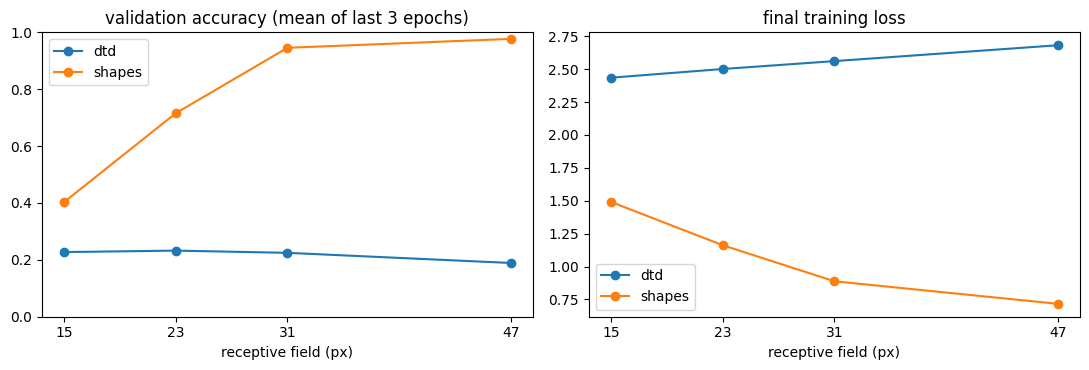

In [11]:
#depthvroute baseline (stacked 3x3 convs) at four receptive fields, one seed, both datasets.
RFS = [15, 23, 31, 47] #potential rfs
RF_SEED = [0]
RF_SETTINGS = dict(REFERENCE, epochs=100, lr_step=25) #long enough for curves to mostly plateau, had to change this a lot but it still is not perfect
#i think i made a mistake here, batch size was supposed to be 32 but was 128 instead, tuning+baseline use 32. i dont think it's a big issue but worth keeping in mind

def run_pilot():
  results = []
  for ds_name, data in DATASETS.items():
    for rf in RFS:
      new = run_seeds(f'pilot_{ds_name[0]}_rf{rf}', depth(rf), data, seeds=RF_SEED, **RF_SETTINGS)
      for r in new:
        r["dataset"], r["rf"] = ds_name, rf
        results.append(r)
  return results

pilot = cache("pilot.json", run_pilot)

# summary table for all rfs
#val acc= mean of the last 3 epochs (validation jumps around between epochs),
print(f"{'dataset':<8}{'RF':>4}{'layers':>8}{'params':>10}{'val acc':>9}{'train loss':>12}{'time (s)':>10}")
for r in sorted(pilot, key=lambda r: (r["dataset"], r["rf"])):
  if r["dataset"] == "shapes":
    n_classes = 9
  else:
    n_classes = 47
  params = sum(p.numel() for p in ConvNet(depth(r["rf"]), n_classes).parameters())
  print(f'{r["dataset"]:<8}{r["rf"]:>4}{((r["rf"] - 1) // 2):>8}{params:>10,}{np.mean(r["val_acc"][-3:]):>9.3f}{r["train_loss"][-1]:>12.3f}{r["seconds"]:>10.0f}')

#graph, rf vs accuracy
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ds_name in sorted({r["dataset"] for r in pilot}):
  rows = sorted([r for r in pilot if r["dataset"] == ds_name], key=lambda r: r["rf"])
  rfs = [r["rf"] for r in rows]
  axes[0].plot(rfs, [np.mean(r["val_acc"][-3:]) for r in rows], marker="o", label=ds_name)
  axes[1].plot(rfs, [r["train_loss"][-1] for r in rows], marker="o", label=ds_name)
axes[0].set_title("validation accuracy (mean of last 3 epochs)"); axes[0].set_ylim(0, 1)
axes[1].set_title("final training loss")
for ax in axes:
    ax.set_xlabel("receptive field (px)"); ax.set_xticks(RFS); ax.legend()
plt.tight_layout(); plt.show()



Tuning (23 as a fixed receptive field, as all 3 routes can reach it (depth, kernel, stride)). DTD is close between rf15 and rf23, whilst shapes does a lot better on rf23, and a receptive field of 23 is large enough that changes in routes are noticeable, whilst not causing optimisation difficulty like 47 and 31 did (training loss increased) with 10 training images (shapes was too easy any higher).

tune_shapes_lr0.0003, seed: 0
  epoch  1  training loss 2.206  training accuracy 0.122  val loss 2.202 val accuracy 0.111    (0 s)
  epoch  2  training loss 2.173  training accuracy 0.178  val loss 2.202 val accuracy 0.111    (1 s)
  epoch  3  training loss 2.153  training accuracy 0.178  val loss 2.203 val accuracy 0.111    (1 s)
  epoch  4  training loss 2.127  training accuracy 0.200  val loss 2.204 val accuracy 0.111    (1 s)
  epoch  5  training loss 2.105  training accuracy 0.211  val loss 2.205 val accuracy 0.111    (2 s)
  epoch  6  training loss 2.071  training accuracy 0.200  val loss 2.205 val accuracy 0.102    (2 s)
  epoch  7  training loss 2.040  training accuracy 0.278  val loss 2.206 val accuracy 0.111    (3 s)
  epoch  8  training loss 2.010  training accuracy 0.278  val loss 2.205 val accuracy 0.111    (3 s)
  epoch  9  training loss 1.990  training accuracy 0.300  val loss 2.204 val accuracy 0.111    (3 s)
  epoch 10  training loss 1.975  training accuracy 0.300  val

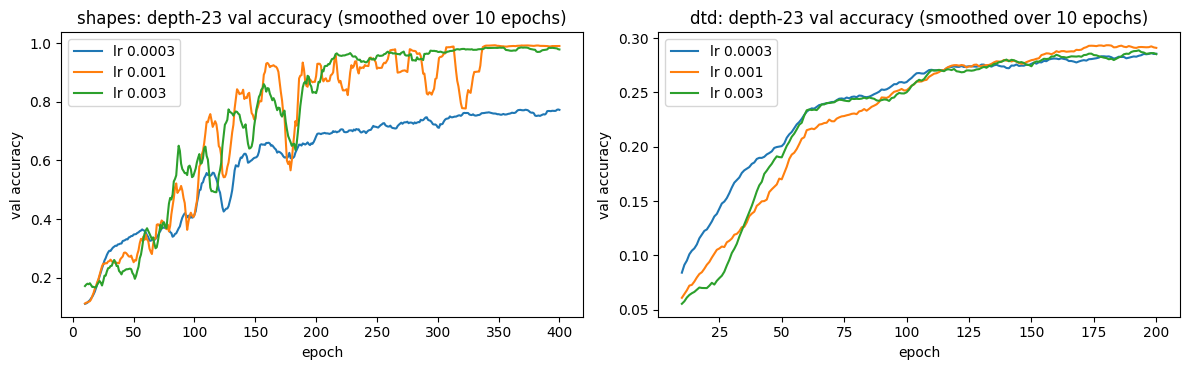

dataset       lr  final val  best val  plateau ep  train loss
shapes    0.0003      0.772     0.777         305       0.752
shapes     0.001      0.990     0.994         235       0.110
shapes     0.003      0.978     0.988         228       0.069
dtd       0.0003      0.286     0.286         104       1.837
dtd        0.001      0.291     0.294         117       1.905
dtd        0.003      0.285     0.289         110       1.730


In [12]:
RF = 23 #target rf chosen by pilot
LRS = [3e-4, 1e-3, 3e-3] #learning rates tried
BUDGETS = {"shapes": dict(epochs=400, lr_step=100), "dtd": dict(epochs=200, lr_step=50)} #long so you can see where training curve flattens
SEEDS_TUNING = {"shapes": [0, 1], "dtd": [0]} #dtd is so slow so only one seed
AVERAGING = 10 #epochs to average over

def run_tuning(ds_name):
  data = DATASETS[ds_name]
  results = []
  for lr in LRS:
    settings = dict(REFERENCE, batch_size = 32, lr=lr, **BUDGETS[ds_name])
    new = run_seeds(f"tune_{ds_name}_lr{lr}", depth(RF), data, seeds=SEEDS_TUNING[ds_name], **settings)
    for r in new:
      r["dataset"] = ds_name
      r["lr"] = lr
    results.extend(new)
  return results

def average(values, n=AVERAGING): #smooths curves
  a = np.asarray(values, dtype=float)
  b = np.convolve(a, np.ones(n) / n, mode="valid")
  return b

def plateau(values, tolerance=0.02, n=AVERAGING): #epoch where the smoothed curve is within tolerance (tolerance chosen by trial and error)
  p = average(values, n)
  return int(np.argmax(p>=p.max()-tolerance)) + n

#one cached file per dataset
tuning = {ds: cache(f"tuning_{ds}.json", lambda ds=ds: run_tuning(ds)) for ds in DATASETS}

#plot for it
fig, axes = plt.subplots(1, len(tuning), figsize=(6 * len(tuning), 3.8), squeeze=False)
for ax, (ds_name, results) in zip(axes[0], tuning.items()):
    for lr in LRS:
        runs = [r for r in results if r["lr"] == lr]
        curves = np.array([average(r["val_acc"]) for r in runs])
        x = np.arange(AVERAGING, AVERAGING + curves.shape[1])
        ax.plot(x, curves.mean(0), label=f"lr {lr:g}")
    ax.set_title(f"{ds_name}: depth:{RF} val accuracy (smoothed over {AVERAGING} epochs)")
    ax.set_xlabel("epoch"); ax.set_ylabel("val accuracy"); ax.legend()
plt.tight_layout(); plt.show()

#really long table
print(f"{'dataset':<8}{'lr':>8}{'final val':>11}{'best val':>10}{'plateau ep':>12}{'train loss':>12}")
for ds_name, results in tuning.items():
    for lr in LRS:
        runs = [r for r in results if r["lr"] == lr]
        final = np.mean([average(r["val_acc"])[-1] for r in runs])
        best  = np.mean([average(r["val_acc"]).max() for r in runs])
        plat  = int(np.median([plateau(r["val_acc"]) for r in runs]))
        loss  = np.mean([r["train_loss"][-1] for r in runs])
        print(f"{ds_name:<8}{lr:>8g}{final:>11.3f}{best:>10.3f}{plat:>12}{loss:>12.3f}")


The 400-epoch run shows the baseline reaches ~0.99 on shapes, so compare networks within a fixed budget of 100 epochs, and re-tune the learning rate at that budget

In [13]:
#with unlimited training the depth 23 baseline reaches ~0.99 on shapes which is unideal since it is not improvable
#instead every network gets the same budget, and we compare how much each learns in it

BUDGET_SHAPES = dict(epochs=100, lr_step=25)
SEEDS_BUDGET = [0, 1, 2]
LRS_BUDGET = [3e-4, 1e-3, 3e-3, 1e-2]

def run_tuning(ds_name, budget=None, seeds=None, tag="", lrs=None):
  data = DATASETS[ds_name]
  budget = budget or BUDGETS[ds_name] #use if given, otherwise use default
  seeds = seeds or SEEDS_TUNING[ds_name]
  results = []
  for lr in (lrs or LRS):
    settings = dict(REFERENCE, batch_size=32, lr=lr, **budget) #override CW2 defaults with our settings
    new = run_seeds(f"tune_{ds_name}{tag}_lr{lr}", depth(RF), data, seeds=seeds, **settings)
    for r in new:
      r["dataset"] = ds_name
      r["lr"] = lr
    results.extend(new)
  return results

tuning_budget = cache("tuning_shapes_budget.json", lambda: run_tuning("shapes", BUDGET_SHAPES, SEEDS_BUDGET, "_budget", lrs=LRS_BUDGET))

#another table
for lr in LRS_BUDGET:
  runs = [r for r in tuning_budget if r["lr"] == lr]
  end = [np.mean(r["val_acc"][-5:]) for r in runs]       # accuracy at the end of the budget
  print(f"lr {lr:g}: val acc at end of budget {np.mean(end):.3f} +- {np.std(end):.3f}  (per seed: {np.round(end, 3)})")

tune_shapes_budget_lr0.0003, seed: 0
  epoch  1  training loss 2.206  training accuracy 0.122  val loss 2.202 val accuracy 0.111    (0 s)
  epoch  2  training loss 2.173  training accuracy 0.178  val loss 2.202 val accuracy 0.111    (1 s)
  epoch  3  training loss 2.153  training accuracy 0.178  val loss 2.203 val accuracy 0.111    (1 s)
  epoch  4  training loss 2.127  training accuracy 0.200  val loss 2.204 val accuracy 0.111    (1 s)
  epoch  5  training loss 2.105  training accuracy 0.211  val loss 2.205 val accuracy 0.111    (2 s)
  epoch  6  training loss 2.071  training accuracy 0.200  val loss 2.205 val accuracy 0.082    (2 s)
  epoch  7  training loss 2.040  training accuracy 0.278  val loss 2.206 val accuracy 0.111    (3 s)
  epoch  8  training loss 2.010  training accuracy 0.278  val loss 2.205 val accuracy 0.111    (3 s)
  epoch  9  training loss 1.991  training accuracy 0.300  val loss 2.203 val accuracy 0.111    (3 s)
  epoch 10  training loss 1.976  training accuracy 0.3

Baseline w/ tuned hyperparameters

In [14]:
B_PARAMS = {"shapes": dict(lr=0.003, epochs=100, lr_step=25), "dtd": dict(lr=0.001, epochs=150, lr_step=38)}
BASELINE_SEEDS = {"shapes": [0,1,2,3,4,5,6,7,8,9], "dtd": [0,1,2,3,4]}
#tuned settings, and at least 5 seeds each, dtd gets less because each one takes like 8 mins

def run_baseline(ds_name):
  #train depth 23 on one dataset for every seed
  settings = dict(REFERENCE, batch_size=32, **B_PARAMS[ds_name])
  results = run_seeds(f"baseline_{ds_name}", depth(RF), DATASETS[ds_name], seeds=BASELINE_SEEDS[ds_name], **settings)

  for r in results:
    r["dataset"] = ds_name
    r["settings"] = B_PARAMS[ds_name] #stored with the results so NB2 can check they match
  return results

#one cache file per dataset -> in QUICK mode both are loaded (to avoid downloading dtd)
baseline = {ds: cache(f"baseline_{ds}.json", lambda ds=ds: run_baseline(ds)) for ds in ["shapes", "dtd"]}

#summary -> test accuracy across seeds
for ds_name, results in baseline.items():
  test = np.array([r["test_acc"] for r in results])
  print(f"{ds_name}: test acc {test.mean():.3f} +- {test.std(ddof=1):.3f} over {len(test)} seeds (per seed: {np.round(test, 3)})")

baseline_shapes, seed: 0
  epoch  1  training loss 2.205  training accuracy 0.100  val loss 2.202 val accuracy 0.111    (0 s)
  epoch  2  training loss 2.142  training accuracy 0.178  val loss 2.181 val accuracy 0.168    (1 s)
  epoch  3  training loss 2.101  training accuracy 0.178  val loss 2.195 val accuracy 0.169    (1 s)
  epoch  4  training loss 2.049  training accuracy 0.222  val loss 2.353 val accuracy 0.159    (1 s)
  epoch  5  training loss 2.031  training accuracy 0.233  val loss 2.386 val accuracy 0.134    (2 s)
  epoch  6  training loss 2.017  training accuracy 0.233  val loss 2.204 val accuracy 0.091    (2 s)
  epoch  7  training loss 1.988  training accuracy 0.244  val loss 2.173 val accuracy 0.144    (3 s)
  epoch  8  training loss 1.967  training accuracy 0.278  val loss 2.142 val accuracy 0.158    (3 s)
  epoch  9  training loss 1.948  training accuracy 0.233  val loss 2.132 val accuracy 0.190    (3 s)
  epoch 10  training loss 1.920  training accuracy 0.278  val loss

In [15]:
!zip -qr nb1_results.zip results data/*.npz #colab only delete before submission
from google.colab import files
files.download("nb1_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
!unzip -l "/content/drive/MyDrive/nb1_results.zip" | grep json #colab only delete before submission
!unzip -o -q "/content/drive/MyDrive/nb1_results.zip" "results/NB1/*" -d .

   110321  2026-11-24 12:01   results/NB1/tuning_shapes_budget.json
    92284  2026-11-24 12:08   results/NB1/baseline_shapes.json
   207037  2026-11-24 11:24   results/NB1/tuning_shapes.json
    55840  2026-11-24 11:54   results/NB1/tuning_dtd.json
    70213  2026-11-24 12:46   results/NB1/baseline_dtd.json
    74302  2026-11-24 11:09   results/NB1/pilot.json


In [22]:
lrs = sorted({r["lr"] for r in json.loads((RESULTS_DIR / "tuning_shapes_budget.json").read_text())}) #colab only delet before submission
print(lrs)

[0.0003, 0.001, 0.003, 0.01]
